# 2014 — Dropout

**Papers:** Geoffrey Hinton, Nitish Srivastava, Alex Krizhevsky, Ilya Sutskever & Ruslan Salakhutdinov, *"Improving neural networks by preventing co-adaptation of feature detectors"* (arXiv 2012); Srivastava et al., *"Dropout: A Simple Way to Prevent Neural Networks from Overfitting"*, JMLR 15 (2014). Used in AlexNet (notebook 17).

Large networks trained on small datasets memorize them. Dropout's fix: during training, **set each hidden unit to zero with probability $p$**, independently for every example and every step.

- No unit can rely on a specific other unit being present, which prevents fragile **co-adaptations**.
- Each step trains a different random sub-network; all $2^n$ of them share weights. At test time you want the **average** of this huge ensemble.
- **Weight scaling** approximates that average cheaply: use the full network and scale activations by the keep probability $1-p$. Modern code uses *inverted dropout* instead: divide by $1-p$ during training, so the test-time network needs no change.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

def load_digits_tensors(size=8, test_size=0.2, seed=0):
    """sklearn's bundled 8x8 handwritten digits (1,797 images, no download needed).
    Returns X_train, y_train, X_test, y_test with X shaped (N, 1, size, size) in [0, 1]."""
    d = load_digits()
    X = torch.tensor(d.images, dtype=torch.float32).unsqueeze(1) / 16.0
    if size != 8:
        X = F.interpolate(X, size=(size, size), mode="bilinear", align_corners=False)
    y = torch.tensor(d.target, dtype=torch.long)
    tr, te = train_test_split(np.arange(len(y)), test_size=test_size, random_state=seed, stratify=d.target)
    return X[tr], y[tr], X[te], y[te]
Xtr, ytr, Xte, yte = [t.to(device) for t in load_digits_tensors()]
Xtr, Xte = Xtr.flatten(1), Xte.flatten(1)
g = torch.Generator().manual_seed(0)
flip = torch.rand(len(ytr), generator=g) < 0.4                              # 40% of training labels replaced at random
y_noisy = ytr.clone().cpu(); y_noisy[flip] = torch.randint(0, 10, (int(flip.sum()),), generator=g); y_noisy, flip = y_noisy.to(device), flip.to(device)
print(f"{len(Xtr)} training images, {int(flip.sum())} with a random label ({(y_noisy[flip] != ytr[flip]).float().mean():.0%} of those are wrong); {len(Xte)} clean test images")

1437 training images, 587 with a random label (90% of those are wrong); 360 clean test images


In [3]:
class MLP(nn.Module):
    """64 → 1024 → 1024 → 10: about 1.1M parameters for ~1,400 examples."""
    def __init__(self, p_hidden=0.0, p_input=0.0, inverted=True):
        super().__init__()
        self.l1, self.l2, self.l3 = nn.Linear(64, 1024), nn.Linear(1024, 1024), nn.Linear(1024, 10)
        self.p_h, self.p_in, self.inverted = p_hidden, p_input, inverted
    def drop(self, x, p):
        if p == 0: return x
        if self.training:
            mask = (torch.rand_like(x) > p).float()
            return x * mask / (1 - p) if self.inverted else x * mask      # inverted: rescale now, nothing at test time
        return x if self.inverted else x * (1 - p)                       # original: scale weights at test time
    def forward(self, x):
        x = self.drop(x, self.p_in)
        x = self.drop(F.relu(self.l1(x)), self.p_h)
        x = self.drop(F.relu(self.l2(x)), self.p_h)
        return self.l3(x)

def train(model, labels, steps=4000, lr=1e-3):
    seed_everything(0); model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr); hist = []
    for s in range(steps):
        model.train(); idx = torch.randint(0, len(Xtr), (64,), device=device)
        loss = F.cross_entropy(model(Xtr[idx]), labels[idx]); opt.zero_grad(); loss.backward(); opt.step()
        if s % 100 == 0 or s == steps - 1:
            model.eval()
            with torch.no_grad():
                hist.append((s, (model(Xte).argmax(1) == yte).float().mean().item(), (model(Xtr[flip]).argmax(1) == labels[flip]).float().mean().item()))
    return model, hist

## Clean labels: dropout is not needed
With all labels correct, this data is easy and every variant reaches about the same test accuracy. Dropout does not add accuracy for free; its job is to stop the network from fitting what it should not.

In [4]:
configs = {"no dropout": (0.0, 0.0), "dropout 0.5 hidden": (0.5, 0.0), "dropout 0.5 hidden + 0.2 input": (0.5, 0.2)}
for name, (ph, pin) in configs.items():
    _, hist = train(MLP(ph, pin), ytr)
    print(f"clean labels, {name:32s} test acc {hist[-1][1]:.3f}")

clean labels, no dropout                       test acc 0.981


clean labels, dropout 0.5 hidden               test acc 0.978


clean labels, dropout 0.5 hidden + 0.2 input   test acc 0.989


## Noisy labels: memorisation vs. generalisation
Now train on the labels where 40% were randomised. A network that fits the training set perfectly must **memorise** the wrong labels, and that hurts the clean test set. We track both: test accuracy, and the fraction of randomised training examples whose *random* label the network reproduces.

noisy labels, no dropout                       test acc 0.722 (best during training 0.942) | random labels memorised 100%


noisy labels, dropout 0.5 hidden               test acc 0.797 (best during training 0.944) | random labels memorised 100%


noisy labels, dropout 0.5 hidden + 0.2 input   test acc 0.900 (best during training 0.969) | random labels memorised 50%


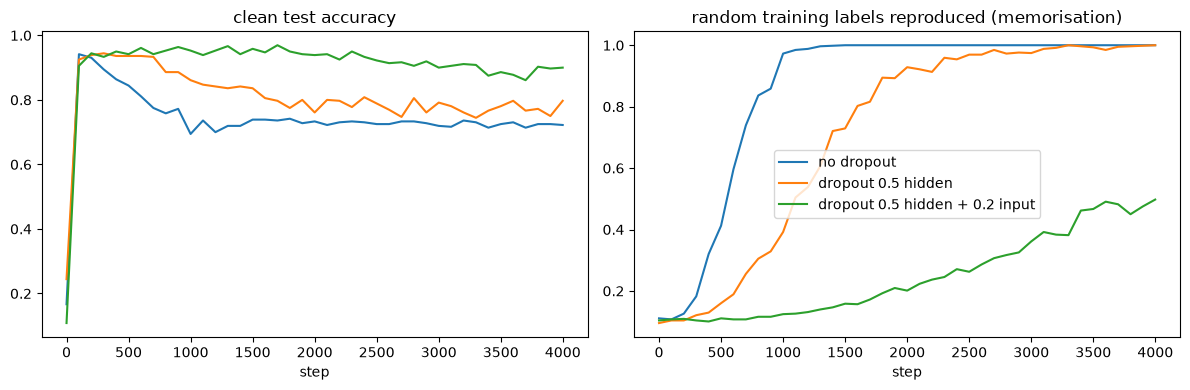

In [5]:
runs = {}
for name, (ph, pin) in configs.items():
    runs[name] = train(MLP(ph, pin), y_noisy)
    s, acc, mem = runs[name][1][-1]
    print(f"noisy labels, {name:32s} test acc {acc:.3f} (best during training {max(h[1] for h in runs[name][1]):.3f}) | random labels memorised {mem:.0%}")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, (_, hist) in runs.items():
    h = np.array(hist)
    axes[0].plot(h[:, 0], h[:, 1], label=name); axes[1].plot(h[:, 0], h[:, 2], label=name)
axes[0].set(title="clean test accuracy", xlabel="step"); axes[1].set(title="random training labels reproduced (memorisation)", xlabel="step"); axes[1].legend()
plt.tight_layout(); plt.show()

Without dropout, test accuracy peaks early (0.94) and then falls to 0.72 as the network memorises every random label. Dropout on the hidden layers alone slows this but still ends with all random labels memorised (0.80). Adding input dropout as well leaves half of them unlearned and keeps test accuracy at 0.90. A random label shares no pattern with other examples, so it can only be stored by a specific co-adapted set of units, and dropout keeps breaking those up.

## Test time: one scaled network ≈ the average of many dropped-out networks
Three ways to predict with the network trained with dropout 0.5 (hidden) and 0.2 (input):
1. **Weight scaling** (what everyone does): one deterministic pass.
2. **Monte Carlo averaging:** keep dropout on and average the softmax over $T$ random masks; the ensemble the scaling approximates. (Gal & Ghahramani, 2016, used the spread of these samples as an uncertainty estimate.)
3. **Forgetting to rescale:** train with non-inverted dropout and test without the $(1-p)$ factor.

In [6]:
model = runs["dropout 0.5 hidden + 0.2 input"][0].eval()                # trained on the noisy labels
with torch.no_grad():
    acc_scaled = (model(Xte).argmax(1) == yte).float().mean().item()
    model.train(); torch.manual_seed(0)
    for T in [1, 10, 100]:
        probs = torch.stack([F.softmax(model(Xte), -1) for _ in range(T)]).mean(0)
        print(f"MC dropout, {T:3d} samples: test acc {(probs.argmax(1) == yte).float().mean().item():.3f}")
    model.eval()
print(f"weight scaling (1 pass):  test acc {acc_scaled:.3f}")
raw, _ = train(MLP(0.5, 0.2, inverted=False), y_noisy); raw.eval()
with torch.no_grad():
    good = (raw(Xte).argmax(1) == yte).float().mean().item()
    conf_good = F.softmax(raw(Xte), -1).max(1).values.mean().item()
    raw.inverted = True                                                  # now the eval path applies no scaling at all
    bad_logits = raw(Xte); bad = (bad_logits.argmax(1) == yte).float().mean().item()
    conf_bad = F.softmax(bad_logits, -1).max(1).values.mean().item()
print(f"non-inverted dropout, tested WITH the (1-p) scaling:    acc {good:.3f}, mean confidence {conf_good:.3f}")
print(f"non-inverted dropout, tested WITHOUT the (1-p) scaling: acc {bad:.3f}, mean confidence {conf_bad:.3f}  (activations too large → overconfident)")

MC dropout,   1 samples: test acc 0.758
MC dropout,  10 samples: test acc 0.933


MC dropout, 100 samples: test acc 0.944
weight scaling (1 pass):  test acc 0.900


non-inverted dropout, tested WITH the (1-p) scaling:    acc 0.942, mean confidence 0.574
non-inverted dropout, tested WITHOUT the (1-p) scaling: acc 0.925, mean confidence 0.940  (activations too large → overconfident)


## Takeaways
- **Dropout is a cheap ensemble.** Training samples sub-networks; testing uses one rescaled network that approximates their average. The approximation is exact only for a linear network: here, after training on noisy labels, averaging 100 dropout masks (0.94) clearly beats the single rescaled pass (0.90), at 100× the cost.
- **It fights memorisation.** On clean, easy data it changes little; when the network could fit things that do not generalise (here, random labels), dropout slows that down dramatically.
- **Today:** with huge datasets and one pass over the data, overfitting is rarely the problem, so most LLM pre-training uses **no dropout** at all. It survives in fine-tuning, in small-data regimes, as attention/residual dropout in some models, and in related ideas such as stochastic depth (dropping whole residual blocks) and DropConnect.